# EDA and cleaning of the five new Miami datasets

This notebook validates ZIP coverage, profiles the datasets, compares coverage, and checks data quality without merging the source tables.

In [2]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').is_dir(): PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / 'data'
NEW_DATA_DIR = DATA_DIR / 'cleaned' / 'new'
ZCTA_PATH = DATA_DIR / 'raw' / 'miami_dade_zctas.txt'
DATASETS = {
    'Miami Home Values': {'path': NEW_DATA_DIR / 'Miami_home_values.csv', 'zip_column': 'RegionName'},
    'Miami Rental Values': {'path': NEW_DATA_DIR / 'Miami_rental_values.csv', 'zip_column': 'RegionName'},
    'Rental Market': {'path': NEW_DATA_DIR / 'Rental-Market.csv', 'zip_column': 'zip_code'},
    'Miami Transit': {'path': NEW_DATA_DIR / 'miami_transit.csv', 'zip_column': 'zip_code'},
    'Rent Trends': {'path': NEW_DATA_DIR / 'rent-trends.csv', 'zip_column': 'zip_code'},
}
def normalize_zip_codes(values):
    return values.astype('string').str.strip().str.replace(r'\.0$', '', regex=True).str.zfill(5)
allowed_zips = {line.strip().zfill(5) for line in ZCTA_PATH.read_text(encoding='utf-8').splitlines() if line.strip()}
if not allowed_zips: raise ValueError(f'Empty Miami-Dade ZIP allowlist: {ZCTA_PATH}')
cleaned_data, validation_rows = {}, []
for dataset_name, config in DATASETS.items():
    path, zip_column = config['path'], config['zip_column']
    frame = pd.read_csv(path, dtype={zip_column: 'string'})
    if zip_column not in frame.columns: raise ValueError(f'{path.name} is missing {zip_column}')
    frame[zip_column] = normalize_zip_codes(frame[zip_column])
    in_scope = frame[zip_column].isin(allowed_zips)
    cleaned_data[dataset_name] = frame.loc[in_scope].copy()
    validation_rows.append({'dataset': dataset_name, 'original_rows': len(frame), 'rows_dropped_outside_miami_dade': int((~in_scope).sum()), 'rows_remaining': int(in_scope.sum()), 'original_columns': len(frame.columns), 'columns_dropped': 0, 'remaining_columns': len(frame.columns), 'out_of_scope_zips': sorted(frame.loc[~in_scope, zip_column].dropna().unique())})
validation_summary = pd.DataFrame(validation_rows)
display(validation_summary.drop(columns='out_of_scope_zips'))
display(validation_summary[['dataset', 'out_of_scope_zips']])

,dataset,original_rows,rows_dropped_outside_miami_dade,rows_remaining,original_columns,columns_dropped,remaining_columns
0,Miami Home Values,30,0,30,17,0,17
1,Miami Rental Values,29,0,29,17,0,17
2,Rental Market,84,0,84,17,0,17
3,Miami Transit,78,0,78,21,0,21
4,Rent Trends,74,0,74,9,0,9


,dataset,out_of_scope_zips
0,Miami Home Values,[]
1,Miami Rental Values,[]
2,Rental Market,[]
3,Miami Transit,[]
4,Rent Trends,[]


## 1. Shapes, schemas, missing values, and duplicates

This section records the baseline schema and audits missing values, duplicate rows, and duplicate ZIP keys. Missing Zillow observations remain missing because they represent unavailable estimates, not zero-dollar values.

In [3]:
schema_rows, missing_rows, duplicate_rows = [], [], []
for dataset_name, config in DATASETS.items():
    frame, zip_column = cleaned_data[dataset_name], config['zip_column']
    schema_rows.append({'dataset': dataset_name, 'rows': len(frame), 'columns': len(frame.columns), 'column_names': ', '.join(frame.columns)})
    duplicate_rows.append({'dataset': dataset_name, 'duplicate_rows': int(frame.duplicated().sum()), 'duplicate_zip_codes': int(frame[zip_column].duplicated().sum())})
    for column in frame.columns: missing_rows.append({'dataset': dataset_name, 'column': column, 'missing_count': int(frame[column].isna().sum()), 'missing_percent': round(frame[column].isna().mean() * 100, 2)})
display(pd.DataFrame(schema_rows))
missing_profile = pd.DataFrame(missing_rows)
display(missing_profile.query('missing_count > 0').sort_values(['dataset', 'missing_count'], ascending=[True, False]))
display(pd.DataFrame(duplicate_rows))
for dataset_name, frame in cleaned_data.items():
    print(f'\n{dataset_name} dtypes')
    display(frame.dtypes.rename('dtype').to_frame())

,dataset,rows,columns,column_names
0,Miami Home Values,30,17,"RegionID, SizeRank, RegionName, RegionType, St..."
1,Miami Rental Values,29,17,"RegionID, SizeRank, RegionName, RegionType, St..."
2,Rental Market,84,17,"zip_code, zori_2026_01, zori_2026_02, zori_202..."
3,Miami Transit,78,21,"zip_code, transit_stop_count, unique_route_cou..."
4,Rent Trends,74,9,"zip_code, latest_rent_usd, rent_3_month_change..."


,dataset,column,missing_count,missing_percent
26,Miami Rental Values,2026-01-31,1,3.45
27,Miami Rental Values,2026-02-28,1,3.45
59,Miami Transit,saturday_departures,3,3.85
60,Miami Transit,sunday_departures,3,3.85
62,Miami Transit,weekend_median_headway_minutes,3,3.85
76,Rent Trends,rent_24_month_change_pct,8,10.81
75,Rent Trends,rent_12_month_change_pct,4,5.41
77,Rent Trends,rent_volatility,4,5.41
35,Rental Market,zori_2026_01,56,66.67
36,Rental Market,zori_2026_02,56,66.67


,dataset,duplicate_rows,duplicate_zip_codes
0,Miami Home Values,0,0
1,Miami Rental Values,0,0
2,Rental Market,0,0
3,Miami Transit,0,0
4,Rent Trends,0,0



Miami Home Values dtypes


,dtype
RegionID,int64
SizeRank,int64
RegionName,string[python]
RegionType,object
StateName,object
State,object
City,object
Metro,object
CountyName,object
2026-01-31,float64



Miami Rental Values dtypes


... (3 outputs left out)


Miami Transit dtypes


,dtype
zip_code,string[python]
transit_stop_count,int64
unique_route_count,int64
transit_types,object
bus_route_count,int64
metrorail_route_count,int64
metromover_route_count,int64
weekday_departures,int64
saturday_departures,float64
sunday_departures,float64



Rent Trends dtypes


,dtype
zip_code,string[python]
latest_rent_usd,float64
rent_3_month_change_pct,float64
rent_12_month_change_pct,float64
rent_24_month_change_pct,float64
rent_volatility,float64
rent_direction,object
source,object
source_date,object


## 2. Numeric profiling and distribution plots

The profile reports descriptive statistics, zero counts, unique values, skewness, and negative values. ZIP identifiers and date columns are excluded from plots.


Miami Home Values numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
RegionID,30.0,0,0,30,72454.866667,23.279017,72426.000000,7.249400e+04,0.342094,0
SizeRank,30.0,0,0,30,4576.566667,3930.984773,532.000000,2.035600e+04,2.329280,0
2026-01-31,30.0,0,0,30,637456.064366,246781.278136,303104.816100,1.522705e+06,2.125660,0
2026-02-28,30.0,0,0,30,638200.375639,247215.932502,301956.361929,1.511917e+06,2.088572,0
2026-03-31,30.0,0,0,30,638571.596977,247255.910840,300867.061280,1.496397e+06,2.046965,0
2026-04-30,30.0,0,0,30,638036.660842,247327.769418,299412.301999,1.483427e+06,2.018276,0
2026-05-31,30.0,0,0,30,637781.322693,247688.854525,298487.466130,1.478049e+06,2.005351,0
2026-06-30,30.0,0,0,30,638844.290351,249661.377210,297789.177069,1.483411e+06,2.010223,0
2026-07-31,30.0,0,0,30,641542.905339,252529.400865,297981.490916,1.493698e+06,2.018991,0
2026-08-31,30.0,0,0,30,645014.663860,256016.623516,298325.005237,1.503923e+06,2.021920,0


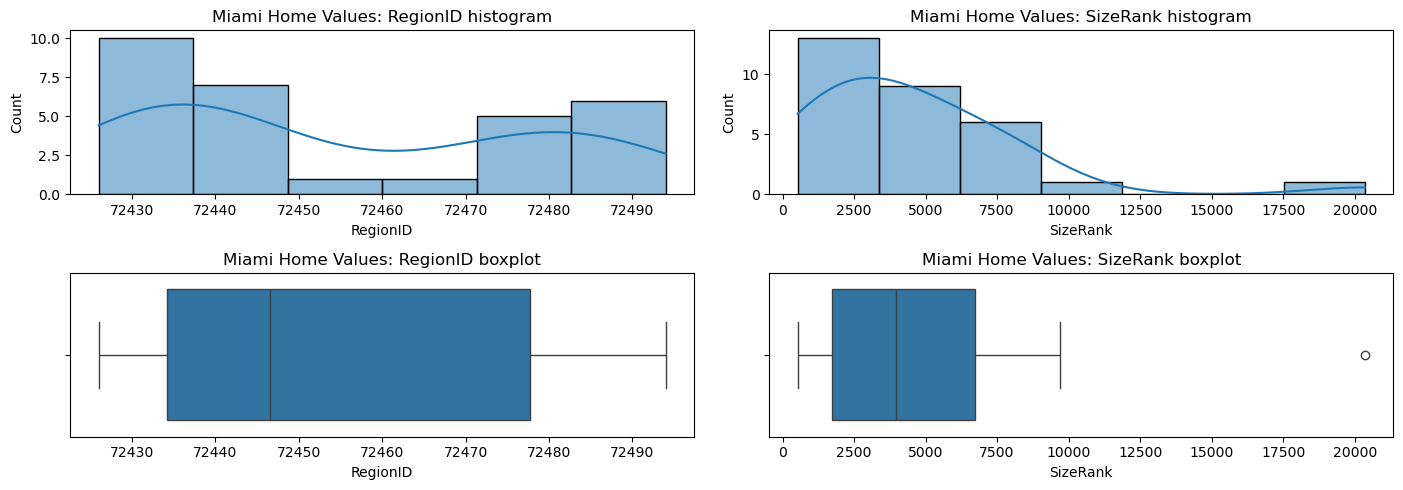


Miami Rental Values numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
RegionID,29.0,0,0,29,72453.689655,22.764483,72426.000000,72494.000000,0.417262,0
SizeRank,29.0,0,0,29,4495.034483,3974.666540,532.000000,20356.000000,2.397594,0
2026-01-31,28.0,1,0,28,2808.393565,484.297892,2122.036267,3856.182758,0.507841,0
2026-02-28,28.0,1,0,28,2815.328313,484.831759,2137.609440,3866.957877,0.526775,0
2026-03-31,29.0,0,0,29,2824.940432,480.865278,2107.030074,3846.303678,0.487892,0
2026-04-30,29.0,0,0,29,2836.546122,485.128576,2100.077129,3859.062284,0.498077,0
2026-05-31,29.0,0,0,29,2838.324590,492.249090,2097.444334,3834.779849,0.450974,0
2026-06-30,29.0,0,0,29,2837.688464,491.790093,2106.902143,3831.772434,0.479971,0
2026-07-31,29.0,0,0,29,2850.054517,486.158263,2127.589713,3813.449590,0.457596,0
2026-08-31,29.0,0,0,29,2857.159062,483.033805,2079.871969,3831.361774,0.458446,0


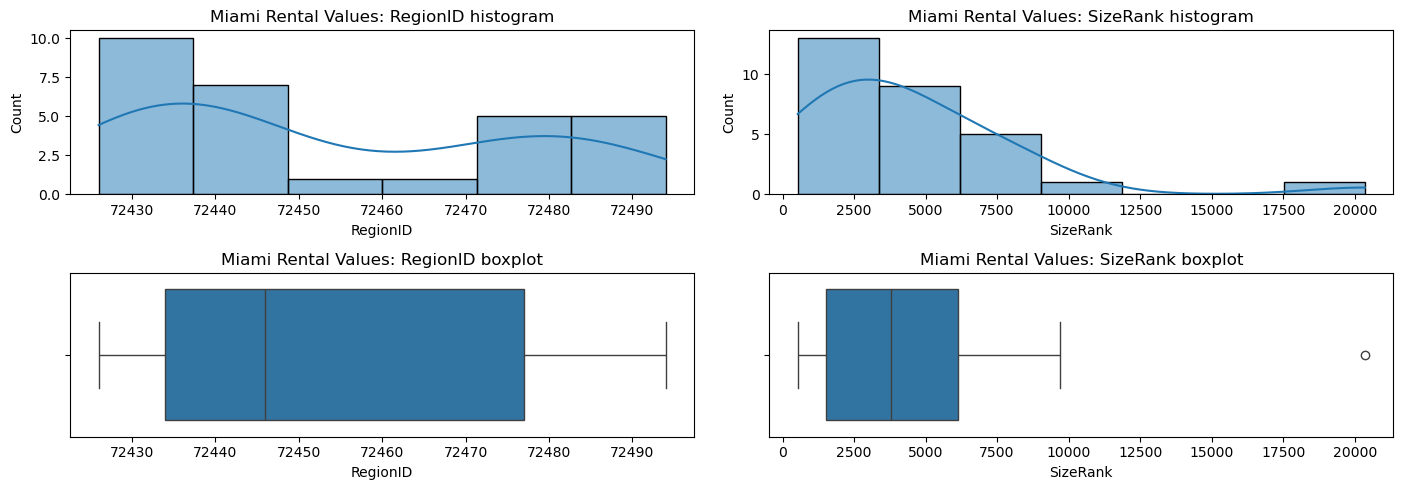


Rental Market numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
zori_2026_01,28.0,56,0,28,2808.393565,484.297892,2122.036267,3856.182758,0.507841,0
zori_2026_02,28.0,56,0,28,2815.328313,484.831759,2137.609440,3866.957877,0.526775,0
zori_2026_03,29.0,55,0,29,2824.940432,480.865278,2107.030074,3846.303678,0.487892,0
zori_2026_04,29.0,55,0,29,2836.546122,485.128576,2100.077129,3859.062284,0.498077,0
zori_2026_05,29.0,55,0,29,2838.324590,492.249090,2097.444334,3834.779849,0.450974,0
zori_2026_06,29.0,55,0,29,2837.688464,491.790093,2106.902143,3831.772434,0.479971,0
zori_2026_07,29.0,55,0,29,2850.054517,486.158263,2127.589713,3813.449590,0.457596,0
zori_2026_08,29.0,55,0,29,2857.159062,483.033805,2079.871969,3831.361774,0.458446,0
zori_latest_rent,29.0,55,0,29,2857.159062,483.033805,2079.871969,3831.361774,0.458446,0
hud_efficiency,84.0,0,0,61,2102.500000,387.891660,1530.000000,2930.000000,0.713876,0


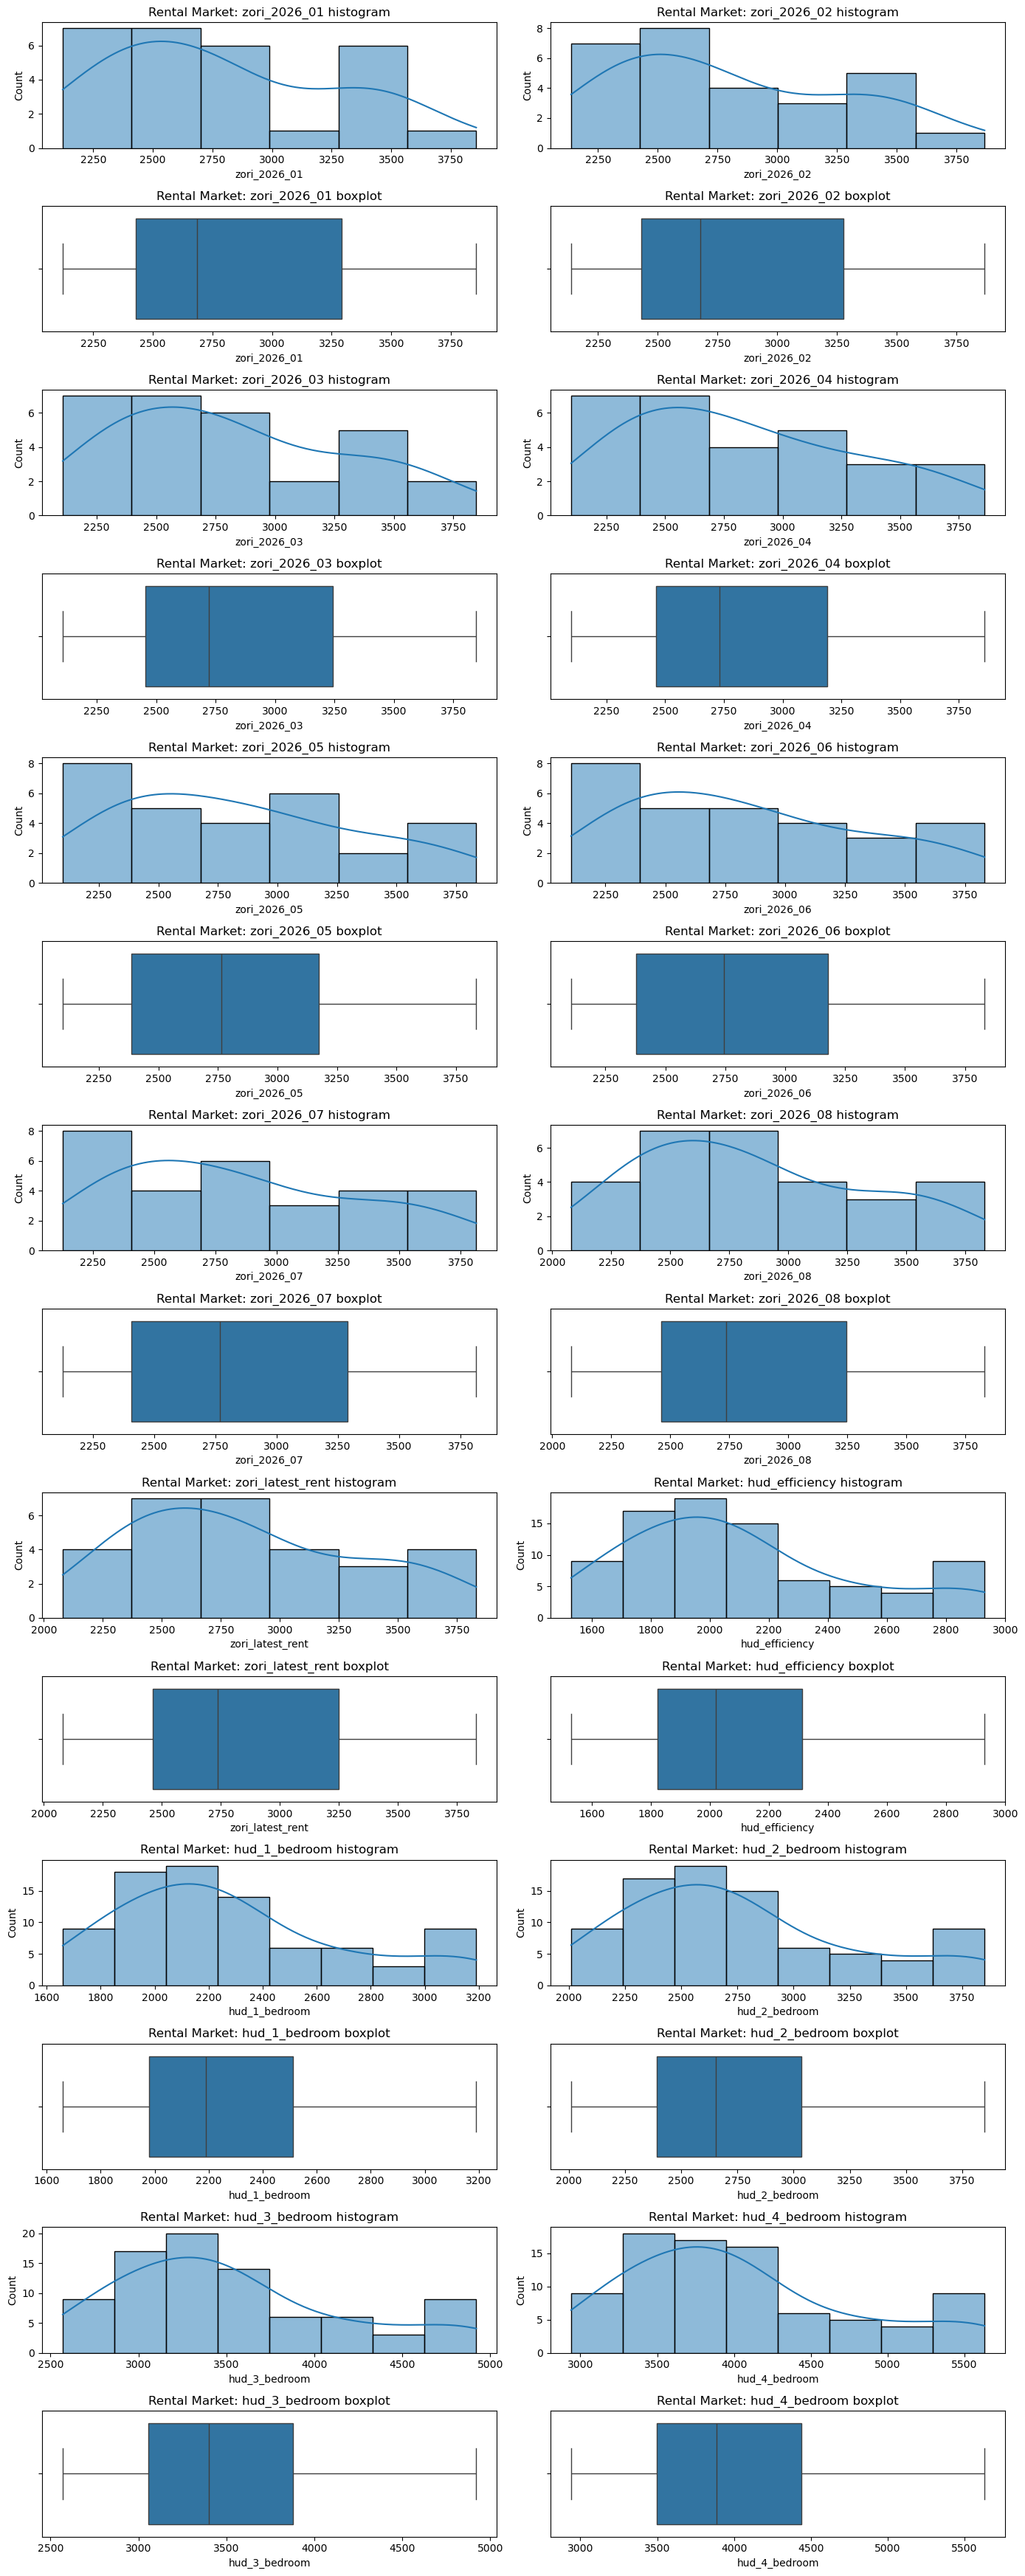


Miami Transit numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
transit_stop_count,78.0,0,0,66,8.905128e+01,54.129690,1.000000e+00,2.510000e+02,0.436088,0
unique_route_count,78.0,0,0,20,8.820513e+00,5.445703,1.000000e+00,2.800000e+01,1.058572,0
bus_route_count,78.0,0,0,21,8.538462e+00,5.031569,1.000000e+00,2.600000e+01,0.894721,0
metrorail_route_count,78.0,0,64,2,1.794872e-01,0.386244,0.000000e+00,1.000000e+00,1.703315,0
metromover_route_count,78.0,0,73,3,1.025641e-01,0.413718,0.000000e+00,2.000000e+00,4.114727,0
weekday_departures,78.0,0,0,78,5.165205e+03,3685.067299,1.500000e+01,1.880200e+04,0.917631,0
saturday_departures,75.0,3,0,75,4.345240e+03,3261.318026,1.500000e+01,1.710000e+04,1.154959,0
sunday_departures,75.0,3,0,74,3.196293e+03,2425.817175,1.400000e+01,1.283700e+04,1.288387,0
weekday_median_headway_minutes,78.0,0,0,46,3.055988e+01,10.724580,9.000000e+00,6.000000e+01,0.713755,0
weekend_median_headway_minutes,75.0,3,0,68,2.494300e+01,18.131652,7.183333e+00,9.723333e+01,2.732612,0


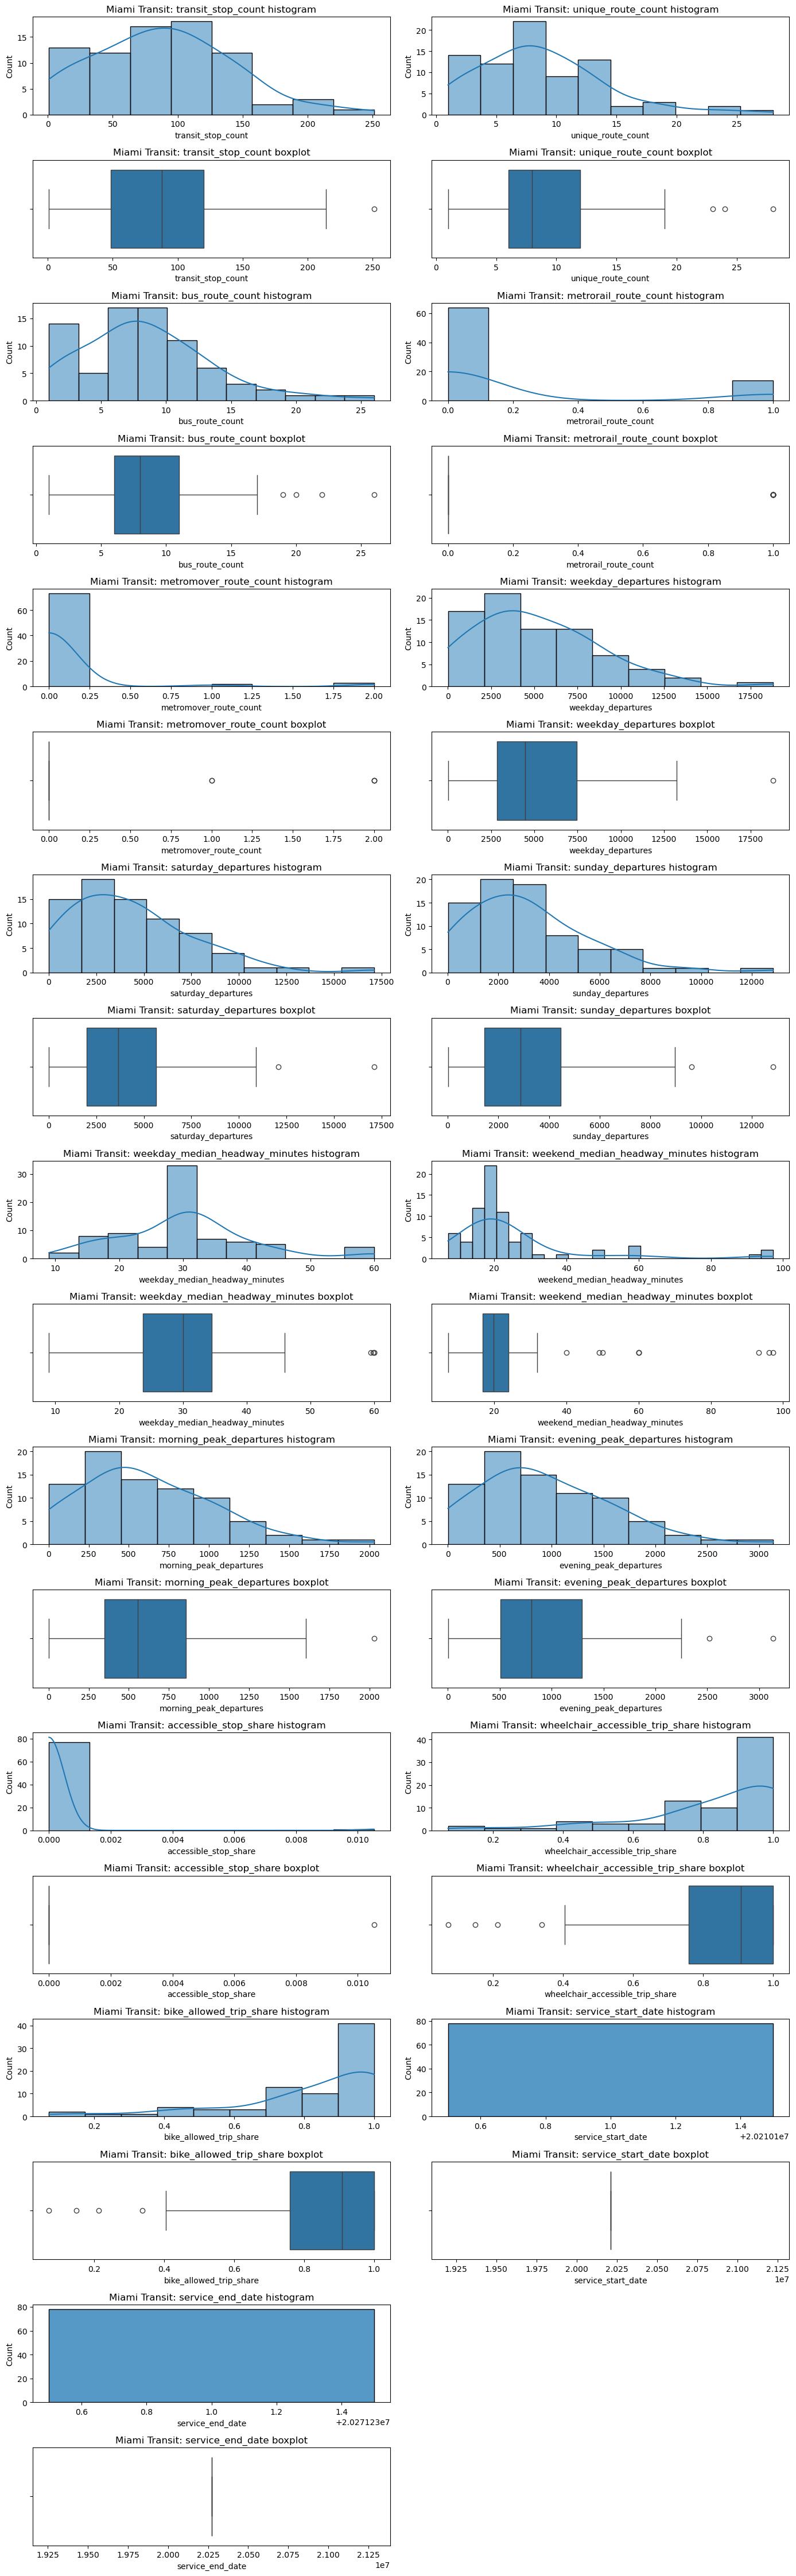


Rent Trends numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
latest_rent_usd,74.0,0,0,74,2817.263804,722.147531,2062.500000,7161.927609,3.414464,0
rent_3_month_change_pct,74.0,0,0,74,0.852271,2.021586,-4.203373,6.899490,0.191988,25
rent_12_month_change_pct,70.0,4,0,70,1.299879,2.257379,-2.650460,8.558722,0.849291,18
rent_24_month_change_pct,66.0,8,0,66,2.186263,3.874457,-5.222038,22.552969,2.230300,15
rent_volatility,70.0,4,0,70,1.139191,0.623766,0.328840,3.176877,1.329227,0


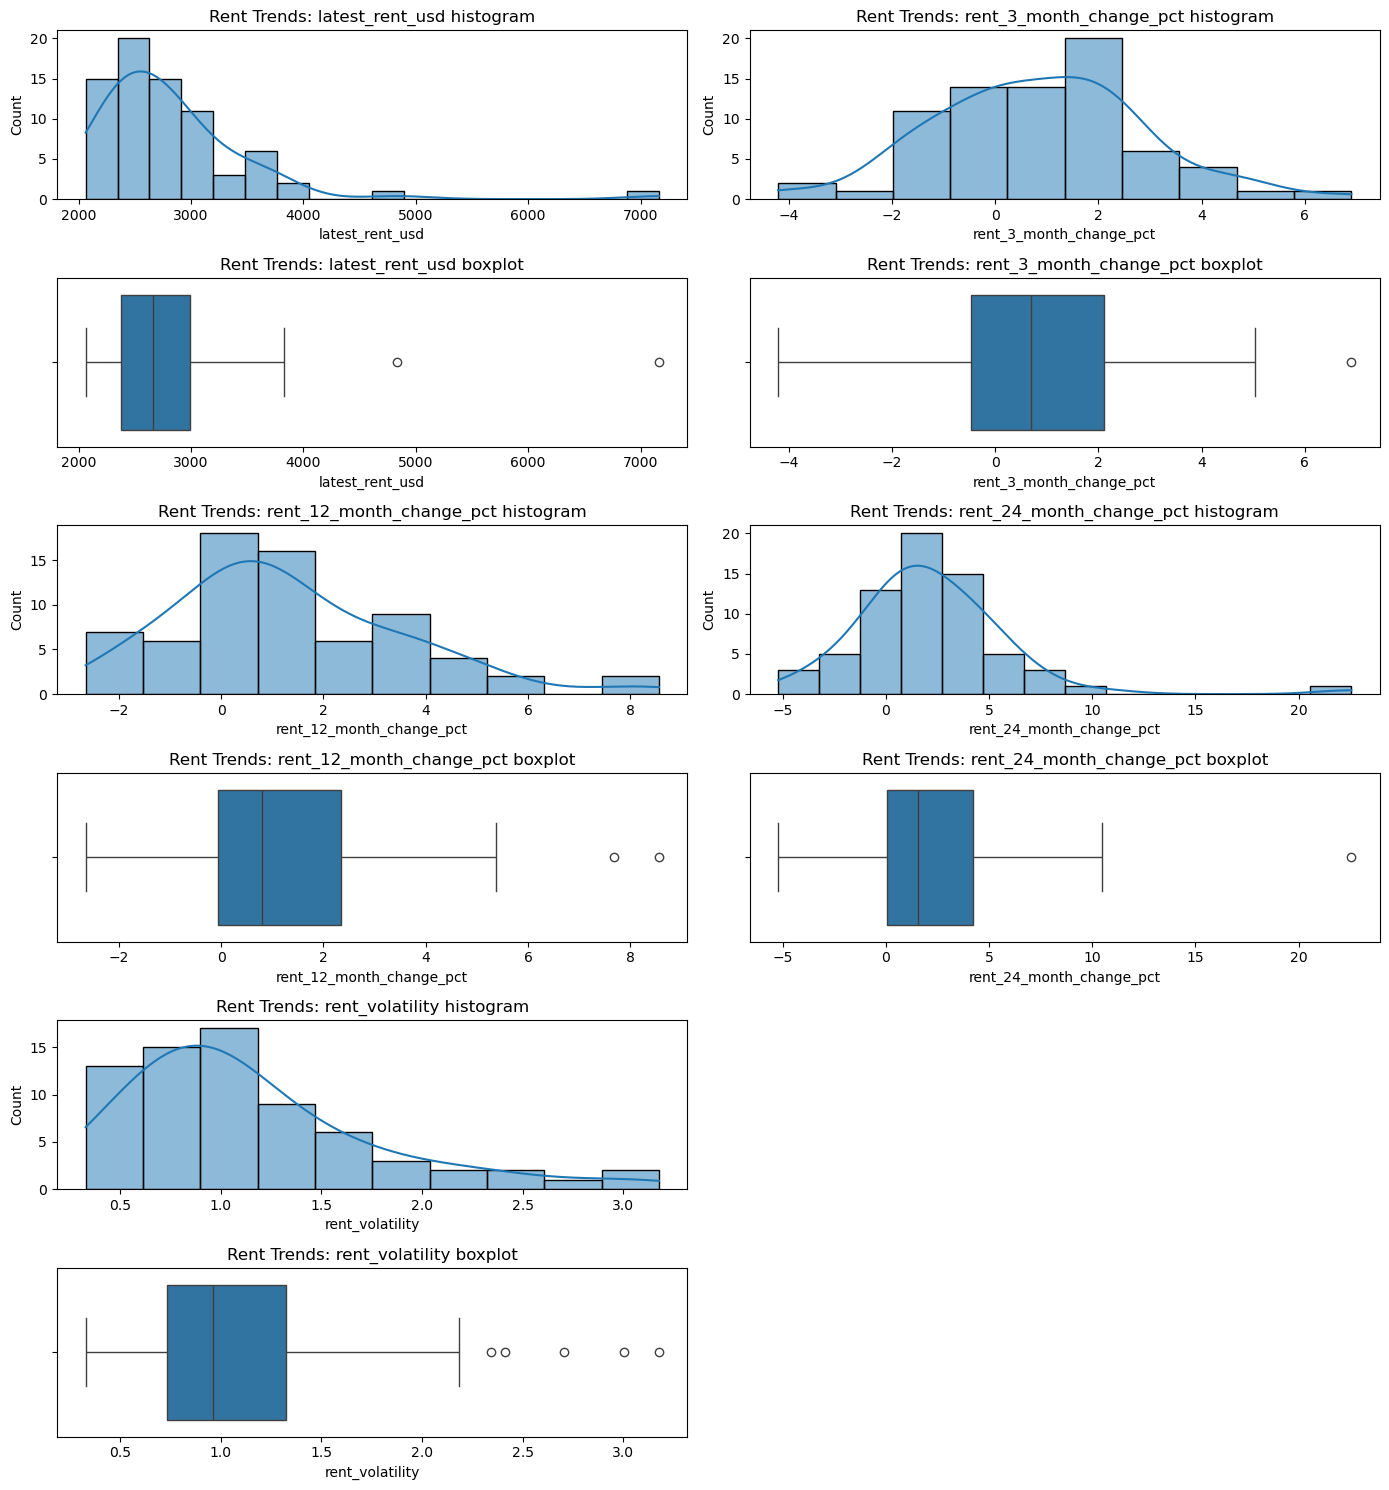

In [ ]:
def profile_numeric_columns(frame):
    numeric = frame.select_dtypes(include='number')
    if numeric.empty: return pd.DataFrame()
    profile = numeric.describe().T
    profile['missing_count'], profile['zero_count'] = numeric.isna().sum(), (numeric == 0).sum()
    profile['unique_count'], profile['skewness'] = numeric.nunique(dropna=True), numeric.skew()
    profile['negative_count'] = (numeric < 0).sum()
    return profile[['count', 'missing_count', 'zero_count', 'unique_count', 'mean', 'std', 'min', 'max', 'skewness', 'negative_count']]


def plot_numeric_distributions(frame, dataset_name, excluded_columns):
    numeric_columns = [c for c in frame.select_dtypes(include='number').columns if c not in set(excluded_columns)]
    if not numeric_columns: print(f'No numeric columns to plot for {dataset_name}.'); return
    columns_per_row, rows = 2, math.ceil(len(numeric_columns) / 2)
    figure, axes = plt.subplots(rows * 2, columns_per_row, figsize=(14, rows * 5), squeeze=False)
    for index, column in enumerate(numeric_columns):
        row, column_index = (index // 2) * 2, index % 2
        values = frame[column].dropna()
        sns.histplot(values, kde=values.nunique() > 1, ax=axes[row, column_index])
        axes[row, column_index].set_title(f'{dataset_name}: {column} histogram')
        sns.boxplot(x=values, ax=axes[row + 1, column_index])
        axes[row + 1, column_index].set_title(f'{dataset_name}: {column} boxplot')
    for index in range(len(numeric_columns), rows * 2):
        row, column_index = (index // 2) * 2, index % 2
        axes[row, column_index].set_visible(False); axes[row + 1, column_index].set_visible(False)
    figure.tight_layout(); plt.show()
for dataset_name, frame in cleaned_data.items():
    print(f'\n{dataset_name} numeric profile')
    display(profile_numeric_columns(frame))
    zip_column = DATASETS[dataset_name]['zip_column']
    date_columns = [c for c in frame.columns if c[:4].isdigit()]
    plot_numeric_distributions(frame, dataset_name, [zip_column, *date_columns])

## 3. Categorical value counts and cross-dataset ZIP coverage

Value counts identify unexpected labels. Coverage comparison identifies the ZIPs shared across all five sources and differences in geographic coverage.

In [5]:
for dataset_name, frame in cleaned_data.items():
    print(f'\n{dataset_name} categorical value counts')
    for column in frame.select_dtypes(exclude='number').columns:
        print(f'{column}:'); display(frame[column].value_counts(dropna=False).rename('count').to_frame())
zip_sets = {name: set(frame[DATASETS[name]['zip_column']].dropna()) for name, frame in cleaned_data.items()}
shared_zips = set.intersection(*zip_sets.values())
coverage_rows = []
for dataset_name, zip_values in zip_sets.items():
    other_zips = set().union(*(values for name, values in zip_sets.items() if name != dataset_name))
    coverage_rows.append({'dataset': dataset_name, 'zip_count': len(zip_values), 'shared_by_all_five': len(shared_zips), 'only_in_this_dataset': len(zip_values - other_zips)})
display(pd.DataFrame(coverage_rows))
print(f'ZIPs shared by all five datasets: {len(shared_zips)}')
display(pd.DataFrame({'shared_zip_code': sorted(shared_zips)}))


Miami Home Values categorical value counts
RegionName:


,count
RegionName,
33177,1
33125,1
33176,1
33165,1
33193,1
33175,1
33126,1
33155,1
33135,1


RegionType:


,count
RegionType,
zip,30


StateName:


,count
StateName,
FL,30


... (43 outputs left out)

,count
source_date,
2026-08,74


,dataset,zip_count,shared_by_all_five,only_in_this_dataset
0,Miami Home Values,30,29,0
1,Miami Rental Values,29,29,0
2,Rental Market,84,29,6
3,Miami Transit,78,29,0
4,Rent Trends,74,29,0


ZIPs shared by all five datasets: 29


,shared_zip_code
0,33122
1,33125
2,33126
3,33127
4,33128
5,33129
6,33130
7,33131
8,33132
9,33133


## 4. Final data-quality checks

These checks confirm that filtered frames contain only Miami-Dade ZCTAs, ZIP codes remain strings, columns are unique, and no configured sentinel values remain.

In [6]:
quality_rows = []
for dataset_name, config in DATASETS.items():
    frame, zip_column = cleaned_data[dataset_name], config['zip_column']
    quality_rows.append({'dataset': dataset_name, 'rows': len(frame), 'zip_dtype': str(frame[zip_column].dtype), 'invalid_zip_rows': int((~frame[zip_column].isin(allowed_zips)).sum()), 'duplicate_rows': int(frame.duplicated().sum()), 'duplicate_columns': int(frame.columns.duplicated().sum()), 'sentinel_values_remaining': int(frame.isin([-666666666, -6666666666]).sum().sum())})
quality_checks = pd.DataFrame(quality_rows)
display(quality_checks)
assert (quality_checks['invalid_zip_rows'] == 0).all()
assert (quality_checks['duplicate_columns'] == 0).all()
assert (quality_checks['sentinel_values_remaining'] == 0).all()
print('All final data-quality checks passed.')

,dataset,rows,zip_dtype,invalid_zip_rows,duplicate_rows,duplicate_columns,sentinel_values_remaining
0,Miami Home Values,30,string,0,0,0,0
1,Miami Rental Values,29,string,0,0,0,0
2,Rental Market,84,string,0,0,0,0
3,Miami Transit,78,string,0,0,0,0
4,Rent Trends,74,string,0,0,0,0


All final data-quality checks passed.
